# Задача 1

## код из семинара

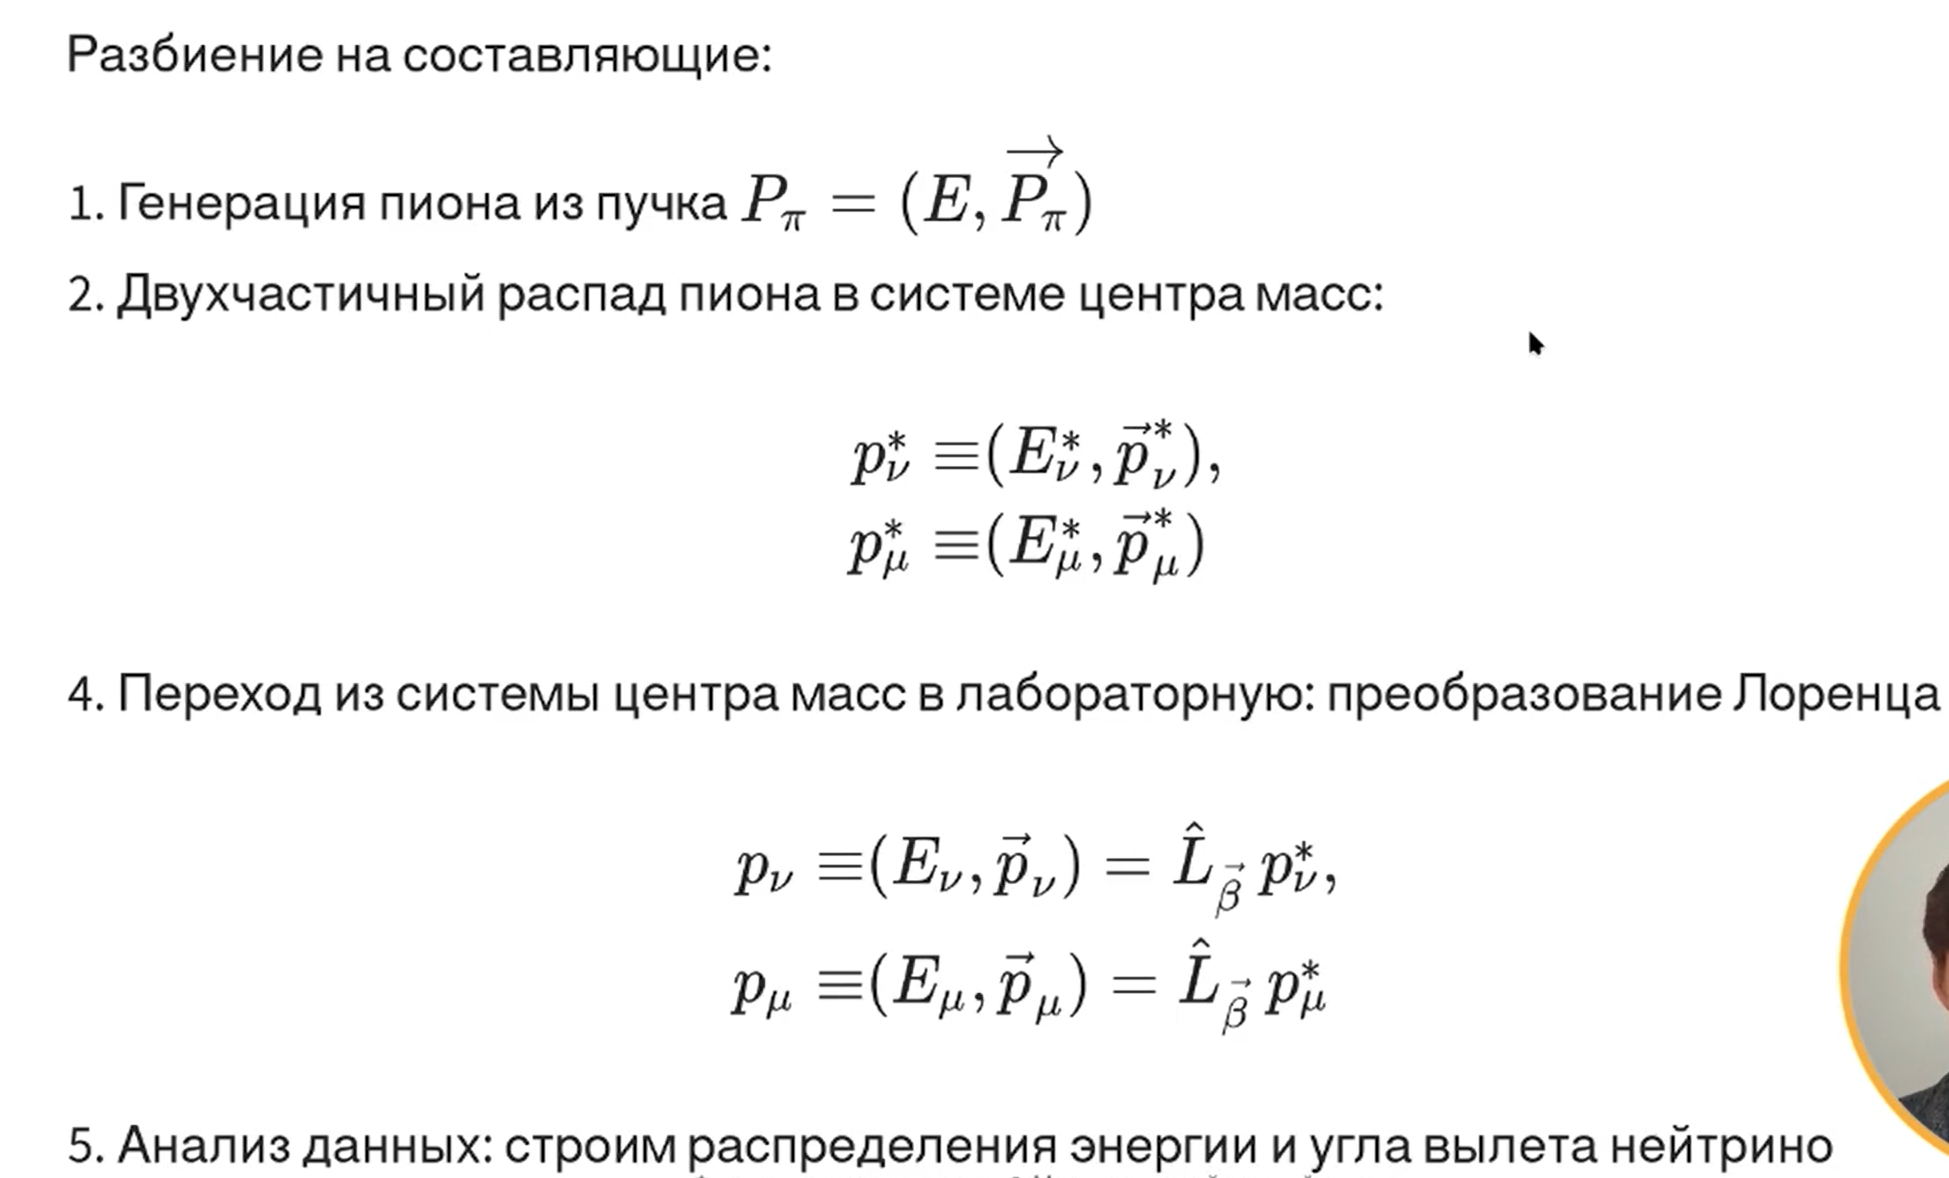

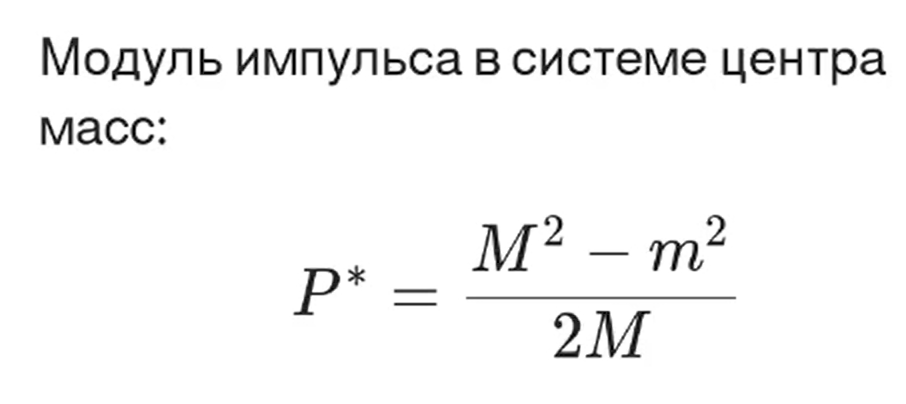

In [1]:
def momentum_in_CM(M:float, m:float):
    '''
    Модуль импульса в системе центра масс
    M -> m1=m, m2=0 
    '''
    P_cm = (M ** 2 - m ** 2) / (2 * M)
    return P_cm

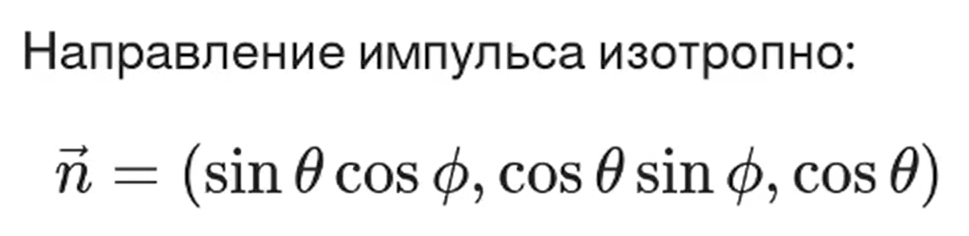

In [2]:
import random 
import math

vector3 = tuple[float, float, float] # псевдоним для кортежа из 3 чисел
def random_direction() -> vector3:
    ''' Розыгрыш случайного направления'''
    phi = random.uniform(0, 2*math.pi)
    cosTheta = random.uniform(-1, 1)
    sinTheta = math.sqrt(1 - cosTheta**2)
    return vector3([sinTheta*math.cos(phi), cosTheta*math.sin(phi), cosTheta])

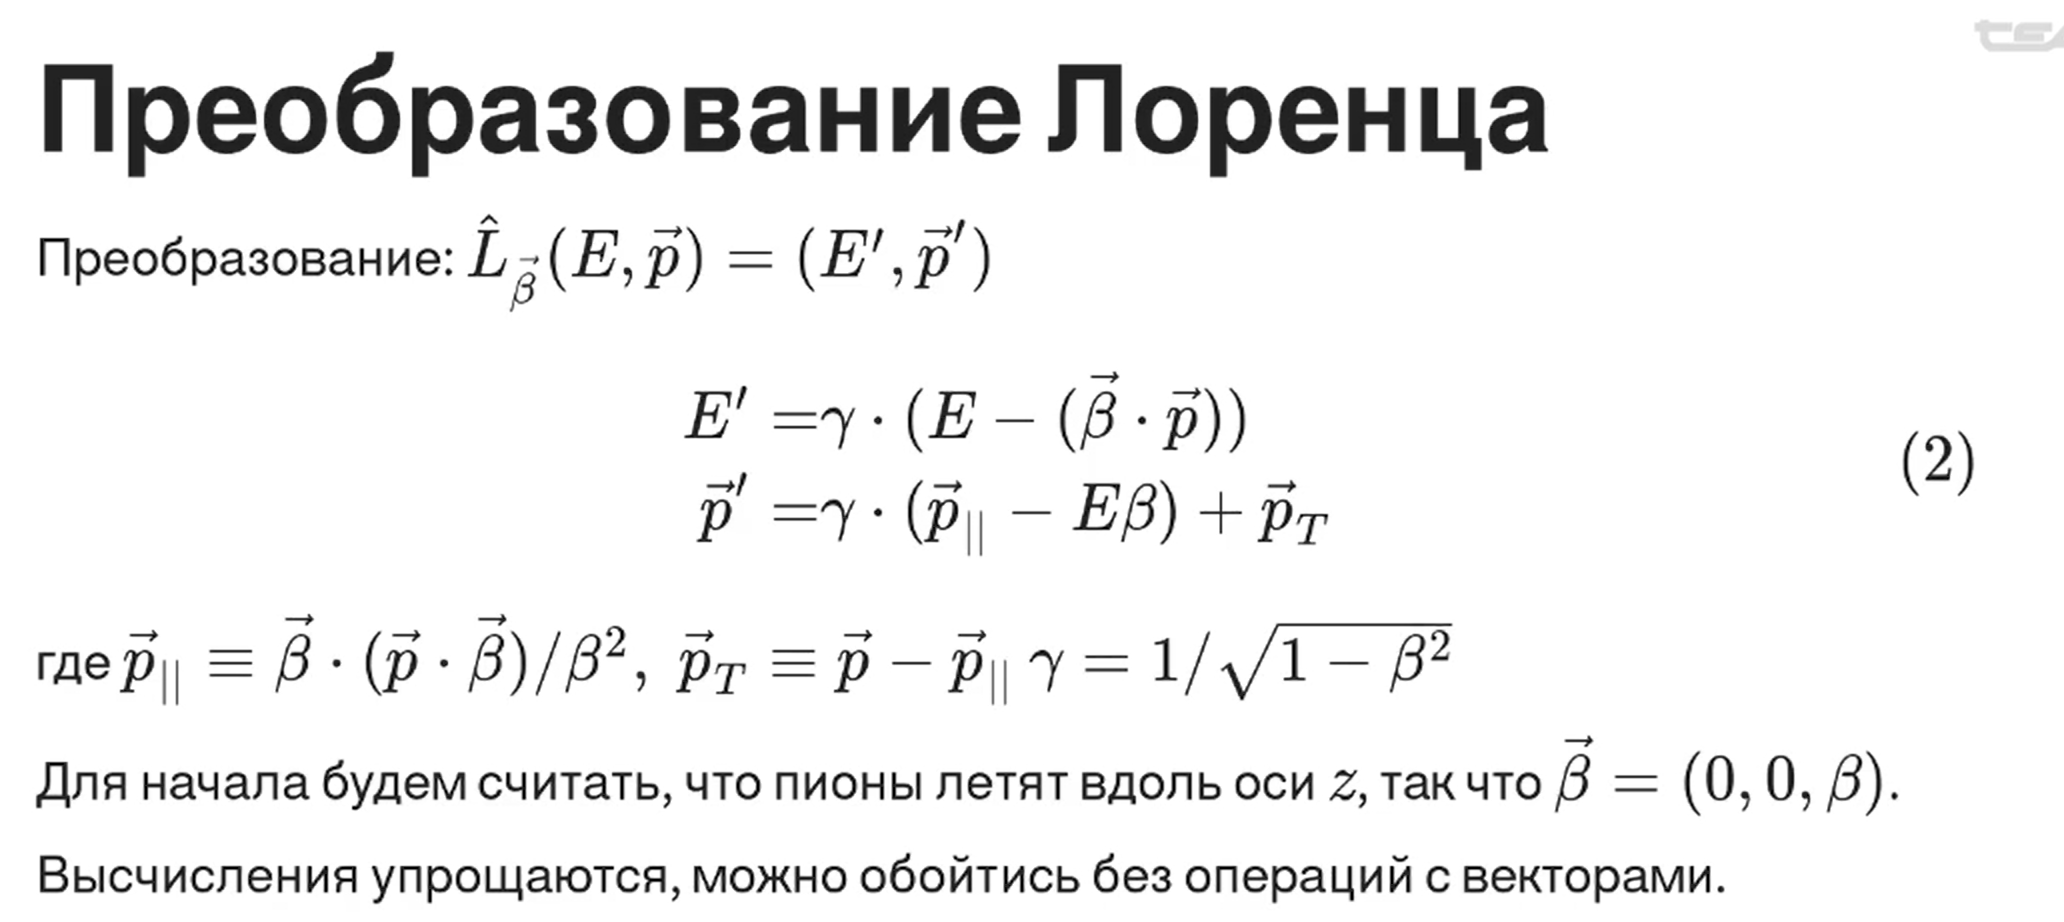

In [3]:
vector4 = tuple[float, vector3]

def lorentz_boost(beta:float, p:vector4) -> vector4:
    '''Преобразование Лоренца вдоль со скоростью бэта вдоль оси z'''
    E, (px, py, pz) = p
    gamma = 1./math.sqrt(1 - beta**2)
    E_lab = gamma * (E - pz*beta)
    pz_lab = gamma * (pz - E*beta)
    p_lab = vector3([px, py, pz_lab])
    return vector4([E_lab, p_lab])

In [6]:
for i in range(100):
    x, y,z = random_direction()
    n2 = x**2 + y**2 + z**2 
    # сравнение чисел с плавающей точкой отдельная боль. Нужно использовать приближенное равенство
    assert abs(n2-1.0) < 1e-10, f"Ошибка нормировки: n2 = {n2} != 1.0"


AssertionError: Ошибка нормировки: n2 = 1.6496653967259132 != 1.0

In [11]:
def test_norm_is_one():
    for i in range(100):
        x, y,z = random_direction()
        n2 = x**2 + y**2 + z**2 
        # сравнение чисел с плавающей точкой отдельная боль. Нужно использовать приближенное равенство
        assert abs(n2-1.0) < 1e-10, f"Ошибка нормировки: n2 = {n2} != 1.0"

def test_mean_is_zero():
    N_samples = 1_000_000
    sx, sy, sz = 0, 0, 0
    for i in range(N_samples):
        x, y, z = random_direction()
        sx+=x
        sy+=y
        sz+=z

    for s in (sx, sy, sz):
        smean = abs(s/N_samples)
        assert smean < 5./math.sqrt(N_samples) , f" Среднее отклонение {smean}  больше 5/{math.sqrt(N_samples)}"

In [9]:
test_norm_is_one()

AssertionError: Ошибка нормировки: n2 = 0.9910770209536508 != 1.0

In [12]:
test_mean_is_zero()

In [ ]:
def test_lorentz_invariant(beta:float, p4:vector4):
    p4_mod = lorentz_boost(beta, p4)
    M2_before = norm2(p_4)
    M2_after = norm2(p4_mod)
    assert is_close(M2_before, M2_after), f"{M2_before} != {M2_after}"

def test_lorentz_invert(beta:float, p4:vector4):
    p4_mod = lorentz_boost(beta, p4)
    p4_inv = lorentz_boost(-beta, p4_mod)
    assert is_close_vec(p4, p4_inv), f"{p4} != {p4_inv}"

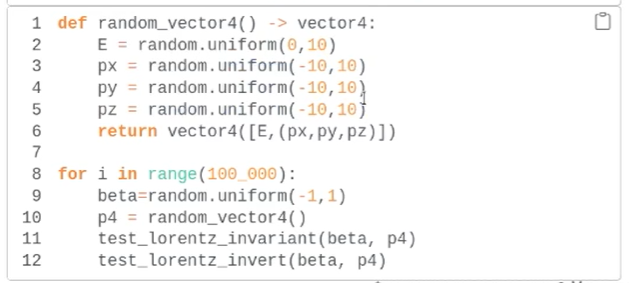

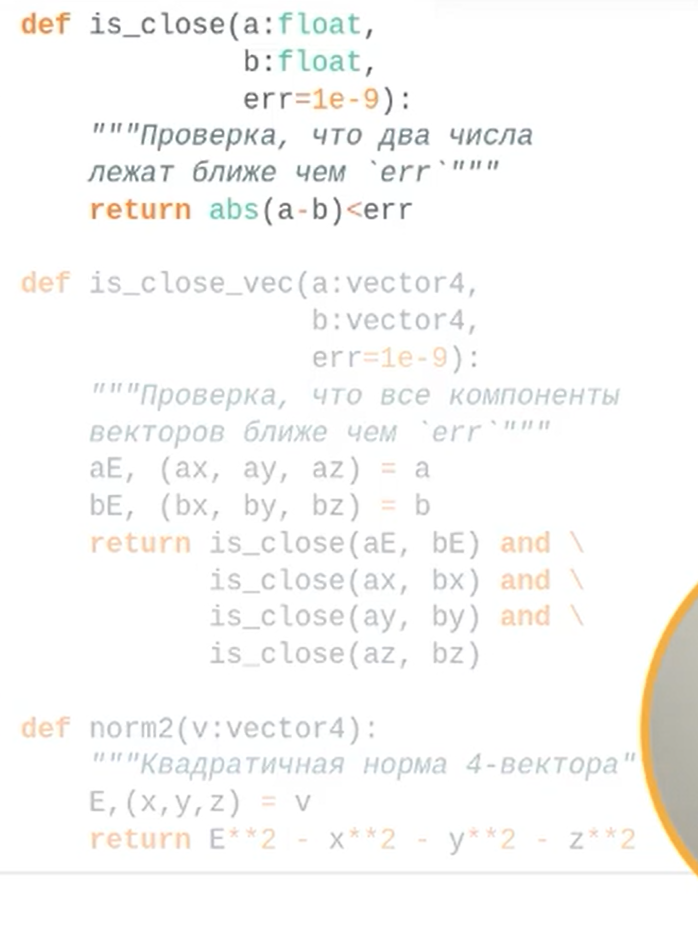

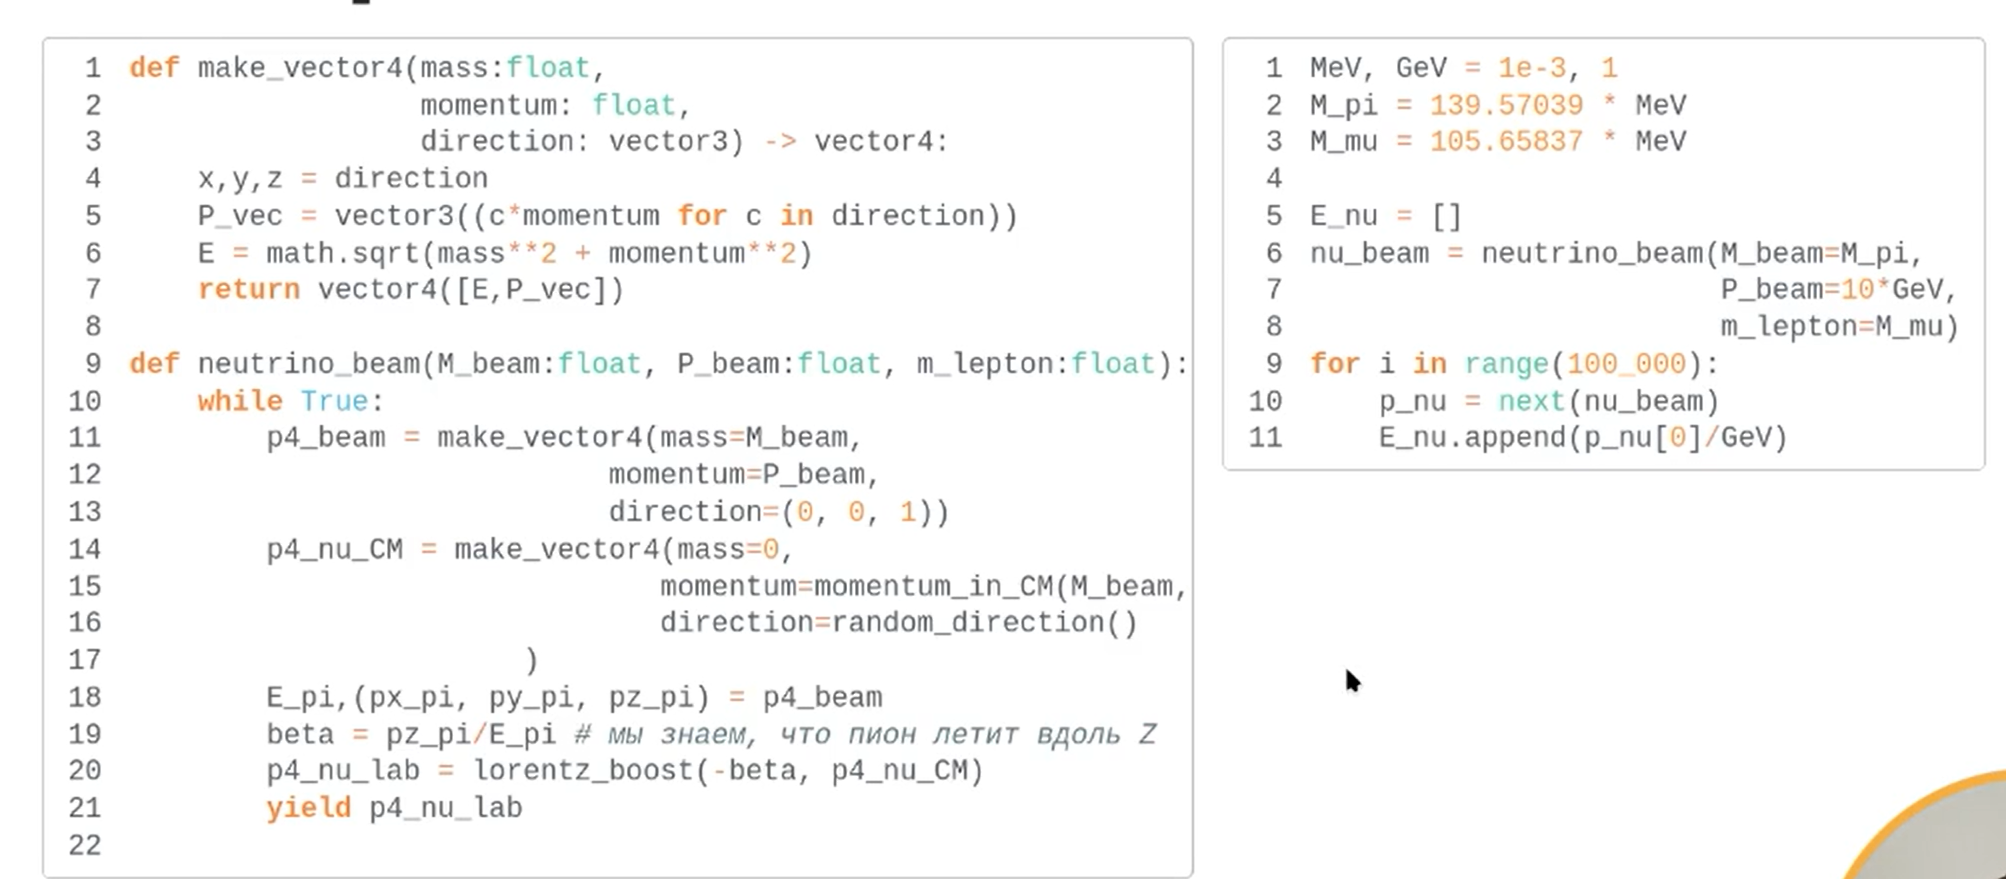

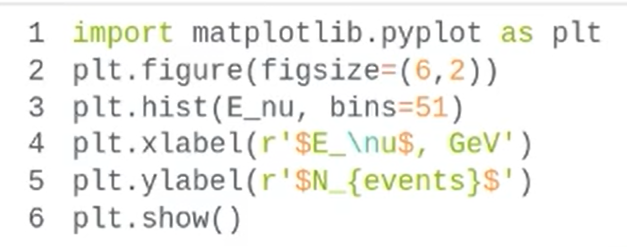

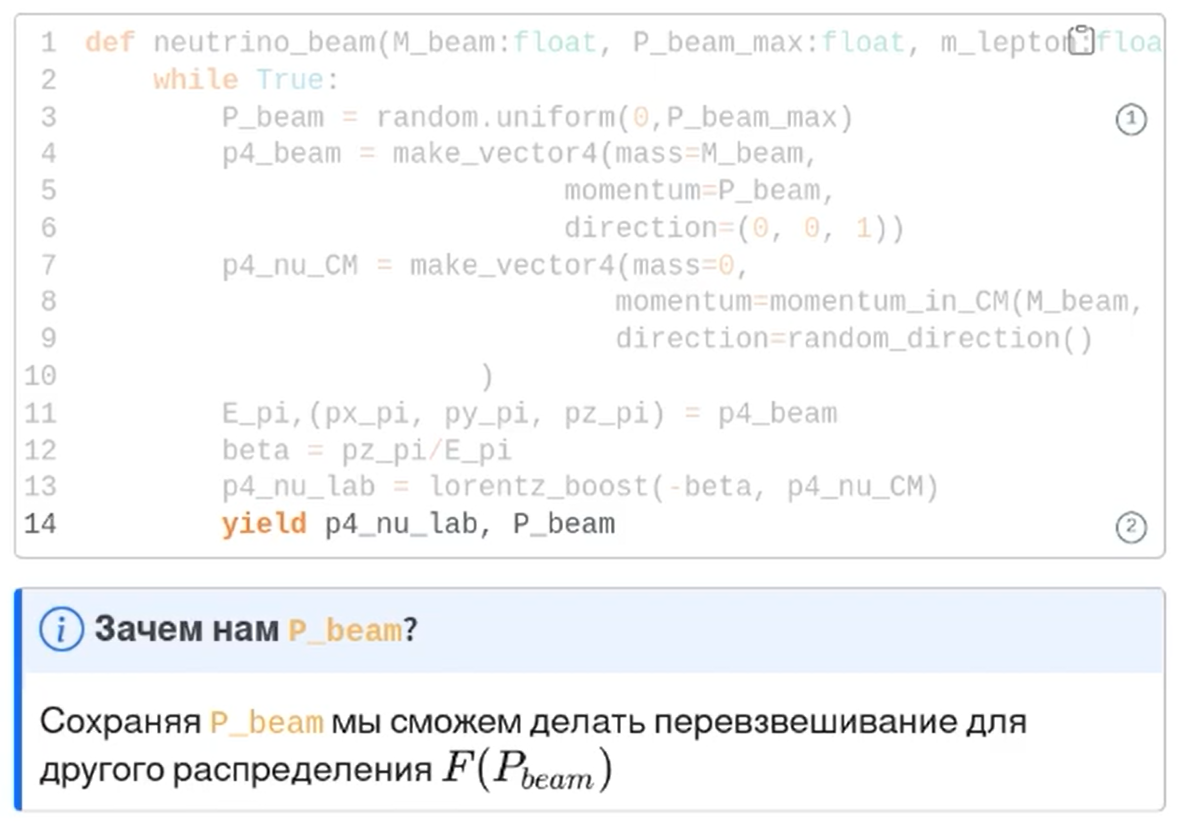

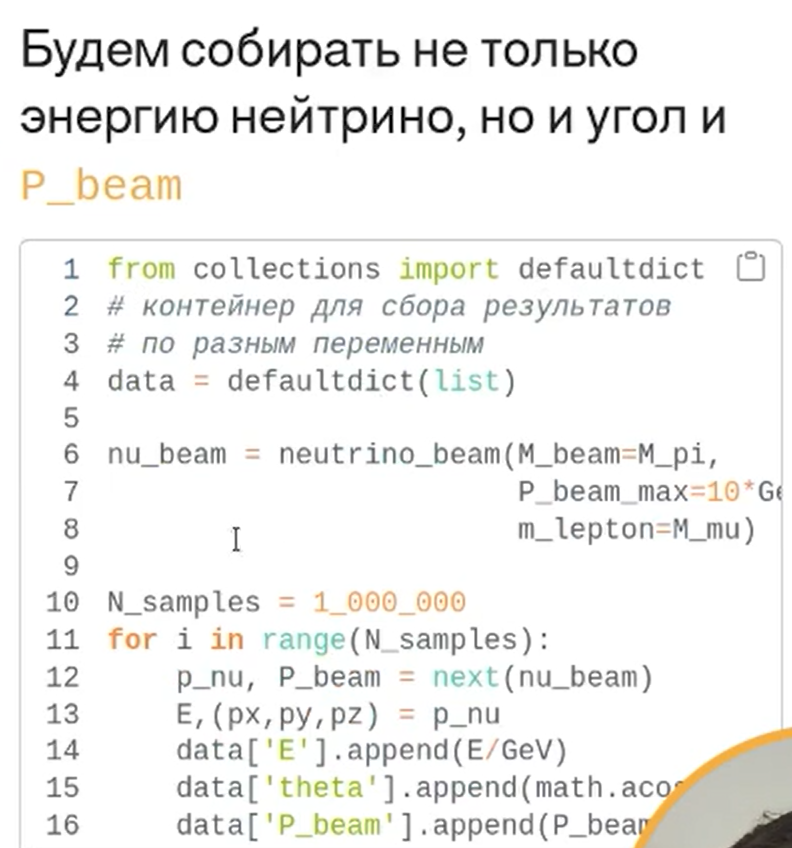

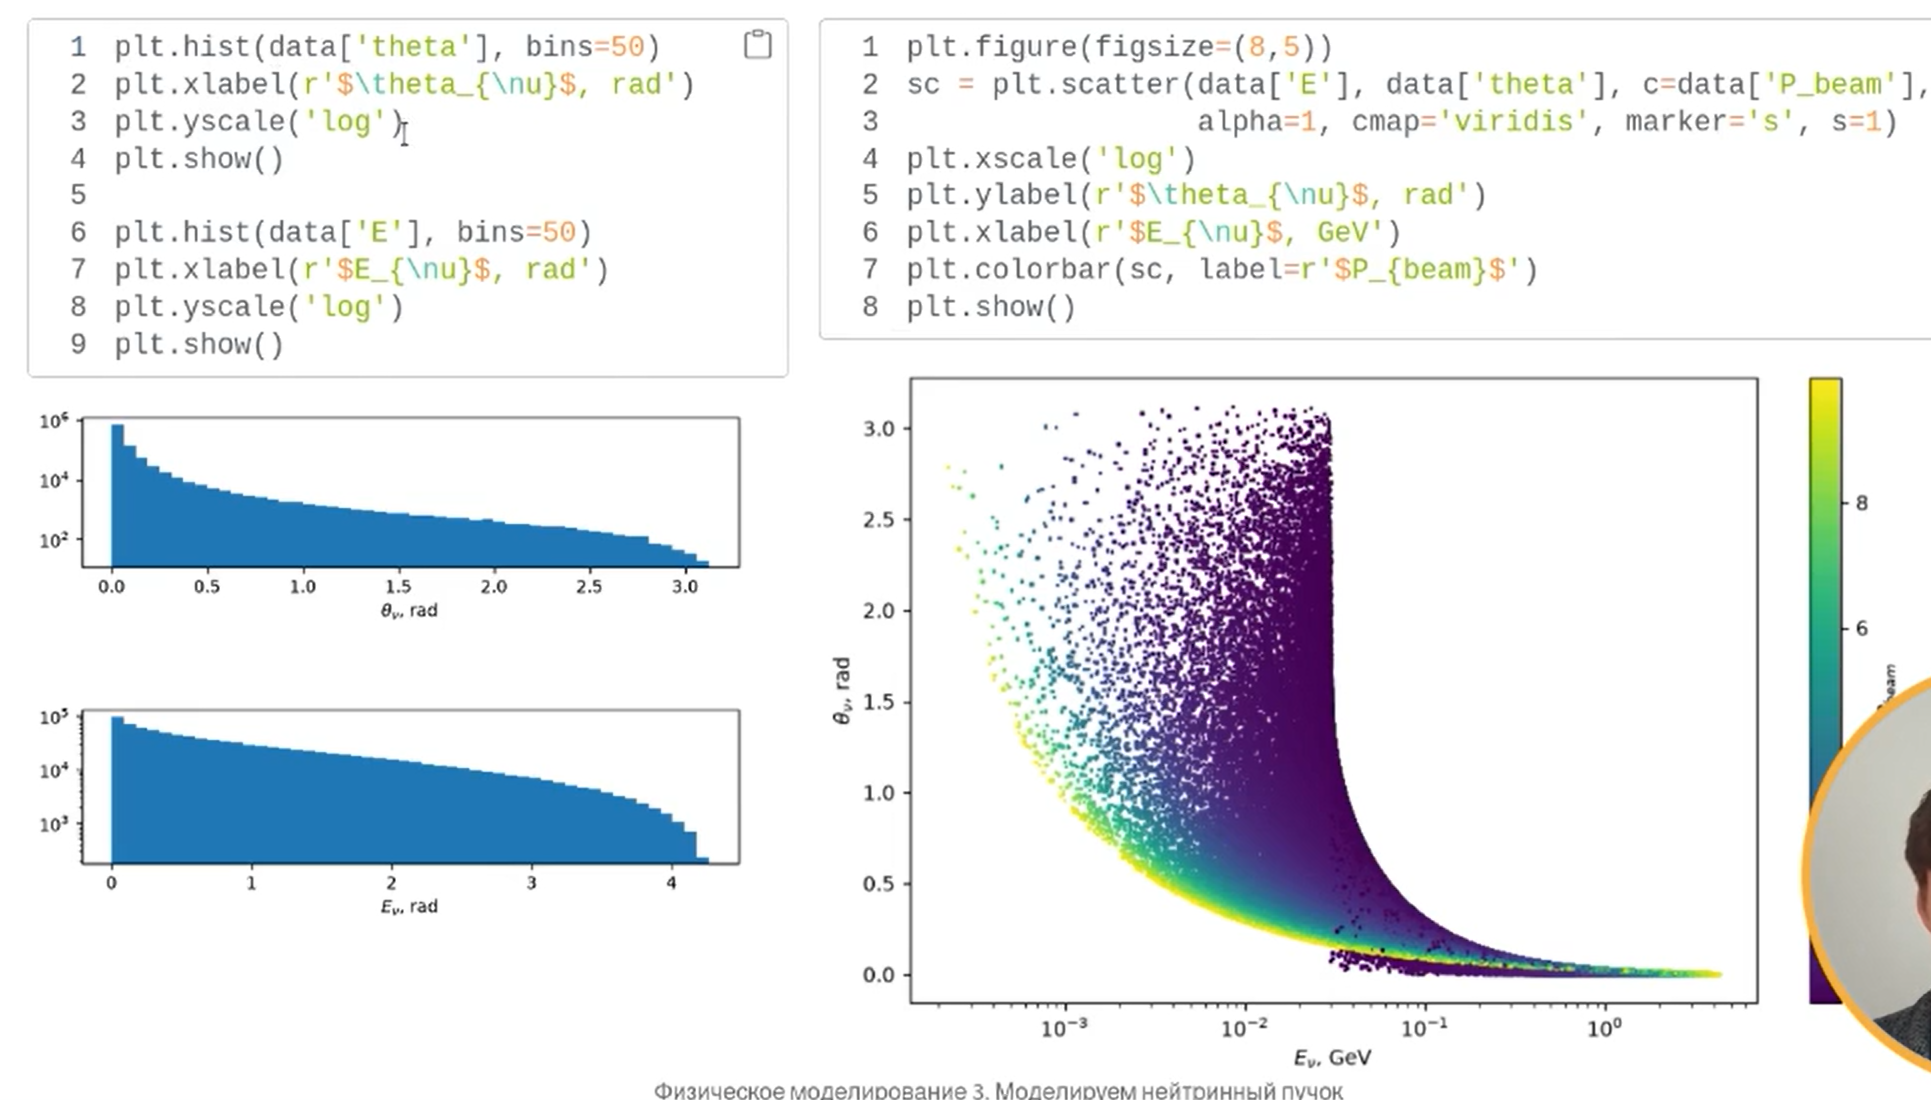

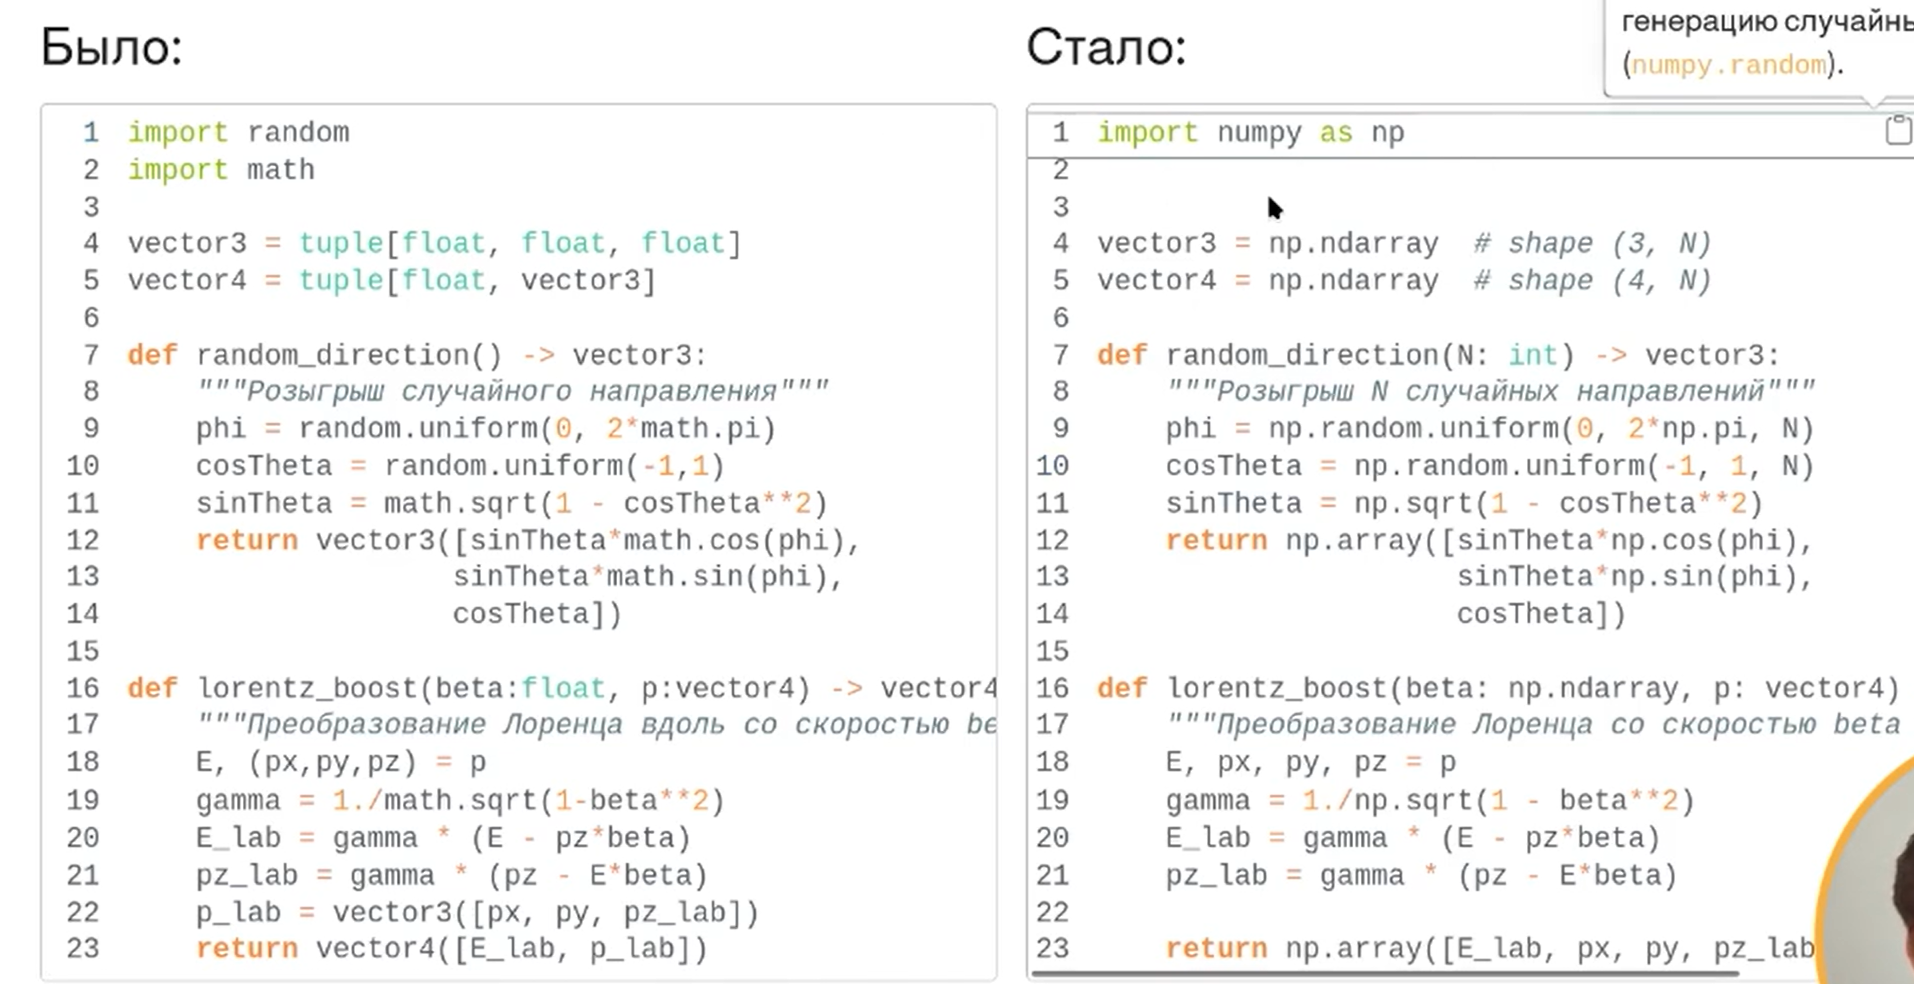